## Medium-horizon cross-sectional momentum, StatArb, and their mixture (50-50 or Huber-regressed)

Saved all_stocks_5yr.csv and prices.csv. Future runs are fully local.

Dataset: 1259 days, 2013-02-08 to 2018-02-07
Building features...
Running walk-forward backtest...

============ OUT-OF-SAMPLE RESULTS ============

         Annual return Annual vol Sharpe Max drawdown Cumulative return Avg daily turnover
Momentum         8.51%      9.94%   0.86       -9.09%             9.21%              8.51%
StatArb         -5.43%      5.66%  -0.96       -7.87%            -5.95%             31.24%
Blend            7.65%      8.54%   0.90       -5.18%             8.34%             24.88%
HuberML          6.96%      8.75%   0.80       -7.99%             7.49%             18.22%


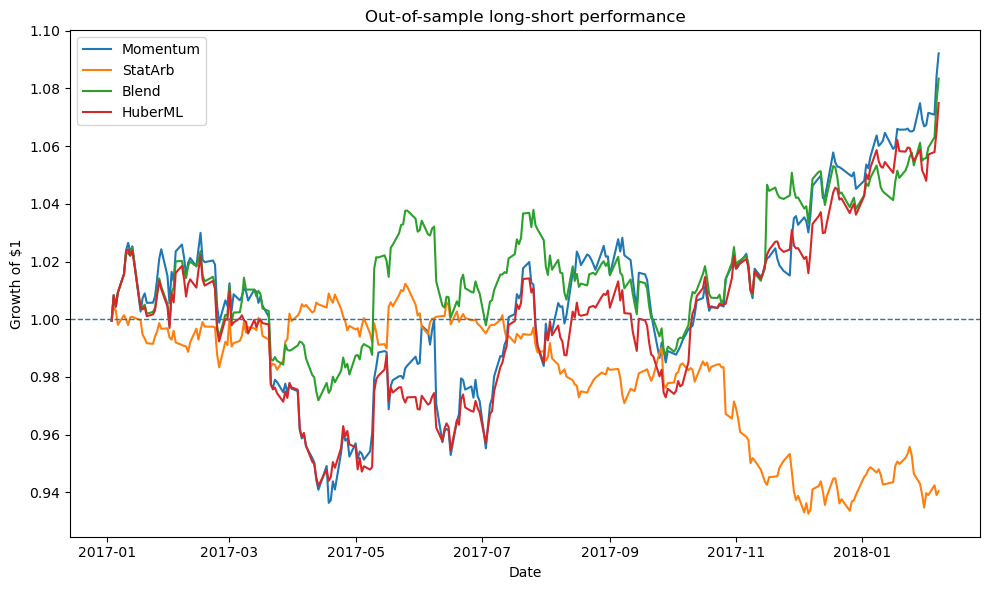

In [3]:

"""
Robust cross-sectional momentum + sector-relative mean reversion.

DATA:
Uses the public Plotly/Kaggle S&P 500 five-year dataset (2013-2018).
On the first run it downloads ONE static CSV from GitHub and creates prices.csv.
Later runs use prices.csv only.

Research comparison:
    1. Momentum
    2. StatArb
    3. 50/50 Blend
    4. HuberML

Install:
    pip install pandas numpy scikit-learn matplotlib

Run:
    python robust_momentum_statarb_static.py
"""

from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler


# ---------------------------------------------------------------------
# 1. SETTINGS
# ---------------------------------------------------------------------

RAW_FILE = Path("all_stocks_5yr.csv")
PRICE_FILE = Path("prices.csv")

# Static public mirror of the Kaggle S&P 500 five-year dataset.
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "plotly/datasets/master/all_stocks_5yr.csv"
)

TEST_START = "2017-01-03"

HORIZON = 5
TRAIN_DAYS = 504
REBALANCE_EVERY = 5
REFIT_EVERY = 20
TOP_FRAC = 0.20
TRANSACTION_COST_BPS = 5.0

SECTORS = {
    "Technology": ["AAPL", "MSFT", "NVDA"],
    "Financials": ["JPM", "BAC", "GS"],
    "Energy": ["XOM", "CVX", "COP"],
    "Consumer": ["WMT", "KO", "PEP"],
}

TICKERS = [x for group in SECTORS.values() for x in group]
FEATURE_NAMES = ["mom_rank", "statarb_rank", "vol20"]


# ---------------------------------------------------------------------
# 2. FIXED DATASET
# ---------------------------------------------------------------------

def build_price_file_from_raw(raw: pd.DataFrame) -> pd.DataFrame:
    """Turn the long-format S&P 500 dataset into a date x ticker close matrix."""
    required = {"date", "close", "Name"}
    missing = required.difference(raw.columns)

    if missing:
        raise ValueError(
            f"Raw dataset is missing columns: {sorted(missing)}"
        )

    raw = raw.copy()
    raw["date"] = pd.to_datetime(raw["date"])
    raw["close"] = pd.to_numeric(raw["close"], errors="coerce")

    raw = raw[raw["Name"].isin(TICKERS)]

    available = set(raw["Name"].dropna().unique())f
    missing_tickers = sorted(set(TICKERS) - available)

    if missing_tickers:
        raise ValueError(
            f"Dataset does not contain required tickers: {missing_tickers}"
        )

    close = raw.pivot(index="date", columns="Name", values="close")
    close = close.reindex(columns=TICKERS)
    close = close.sort_index().dropna(how="any")

    if len(close) < 750:
        raise RuntimeError(
            f"Only {len(close)} common trading days remain; expected much more."
        )

    close.to_csv(PRICE_FILE)
    return close


def load_prices() -> pd.DataFrame:
    """
    Data priority:
        1. prices.csv              -> use immediately
        2. all_stocks_5yr.csv     -> build prices.csv
        3. otherwise download ONE static GitHub CSV, then cache both files
    """
    if PRICE_FILE.exists():
        print(f"Loading {PRICE_FILE} ...")
        close = pd.read_csv(
            PRICE_FILE,
            index_col=0,
            parse_dates=True,
        )
        return close[TICKERS].sort_index()

    if RAW_FILE.exists():
        print(f"Using local {RAW_FILE} ...")
        raw = pd.read_csv(RAW_FILE)
        return build_price_file_from_raw(raw)

    print("Downloading one fixed public dataset from GitHub ...")

    try:
        raw = pd.read_csv(DATA_URL)
    except Exception as exc:
        raise RuntimeError(
            "\nCould not download the static dataset.\n\n"
            "Manual fallback:\n"
            "1. Open the Plotly GitHub dataset 'all_stocks_5yr.csv'.\n"
            "2. Download it into the same folder as this script.\n"
            "3. Re-run the script.\n\n"
            f"Original error: {exc}"
        ) from exc

    # Cache the raw file so no web request is needed again.
    raw.to_csv(RAW_FILE, index=False)

    close = build_price_file_from_raw(raw)

    print(
        f"Saved {RAW_FILE} and {PRICE_FILE}. "
        "Future runs are fully local."
    )

    return close


# ---------------------------------------------------------------------
# 3. FEATURES
# ---------------------------------------------------------------------

def cross_sectional_rank(df: pd.DataFrame) -> pd.DataFrame:
    return df.rank(axis=1, pct=True) - 0.5


def build_features(close: pd.DataFrame) -> dict:
    returns = close.pct_change()

    # Medium-term continuation: ~6 months to ~1 month ago.
    mom_6_1 = close.shift(21) / close.shift(126) - 1.0
    mom_rank = cross_sectional_rank(mom_6_1)

    # Risk feature and later position-sizing input.
    vol20 = returns.rolling(20, min_periods=20).std()

    # -------------------------------------------------------------
    # Sector-relative residual mean reversion.
    # -------------------------------------------------------------
    residuals = pd.DataFrame(
        np.nan,
        index=close.index,
        columns=close.columns,
    )

    for members in SECTORS.values():
        for stock in members:
            peers = [x for x in members if x != stock]

            # Leave-one-out peer factor.
            peer_return = returns[peers].mean(axis=1)

            cov = returns[stock].rolling(
                60, min_periods=40
            ).cov(peer_return)

            var = peer_return.rolling(
                60, min_periods=40
            ).var()

            # Yesterday's beta is used for today's residual.
            beta = (
                cov / var.replace(0.0, np.nan)
            ).shift(1)

            residuals[stock] = (
                returns[stock] - beta * peer_return
            )

    residual_5d = residuals.rolling(
        5, min_periods=5
    ).sum()

    residual_mean = residual_5d.rolling(
        60, min_periods=40
    ).mean()

    residual_std = residual_5d.rolling(
        60, min_periods=40
    ).std()

    residual_z = (
        (residual_5d - residual_mean)
        / residual_std.replace(0.0, np.nan)
    )

    # Negative relative displacement -> positive rebound score.
    statarb_rank = cross_sectional_rank(-residual_z)

    # Five-day forward target.
    forward_return = (
        close.shift(-HORIZON) / close - 1.0
    )

    # Risk-normalised target.
    target = (
        forward_return
        / (vol20 * math.sqrt(HORIZON))
    ).clip(-5.0, 5.0)

    return {
        "returns": returns,
        "mom_rank": mom_rank,
        "statarb_rank": statarb_rank,
        "vol20": vol20,
        "target": target,
    }


# ---------------------------------------------------------------------
# 4. PANEL REGRESSION DATA
# ---------------------------------------------------------------------

def make_training_panel(
    features: dict,
    start_idx: int,
    end_idx: int,
) -> pd.DataFrame:

    dates = features["returns"].index[
        start_idx:end_idx + 1
    ]

    rows = []

    for dt in dates:
        for stock in TICKERS:
            rows.append({
                "date": dt,
                "stock": stock,
                "mom_rank":
                    features["mom_rank"].at[dt, stock],
                "statarb_rank":
                    features["statarb_rank"].at[dt, stock],
                "vol20":
                    features["vol20"].at[dt, stock],
                "target":
                    features["target"].at[dt, stock],
            })

    return pd.DataFrame(rows).dropna()


def fit_huber(panel: pd.DataFrame) -> Pipeline:
    model = Pipeline([
        ("scale", RobustScaler()),
        (
            "model",
            HuberRegressor(
                epsilon=1.35,
                alpha=1e-4,
                max_iter=1000,
            ),
        ),
    ])

    model.fit(
        panel[FEATURE_NAMES],
        panel["target"],
    )

    return model


# ---------------------------------------------------------------------
# 5. PORTFOLIO
# ---------------------------------------------------------------------

def signal_to_weights(
    signal: pd.Series,
    vol: pd.Series,
) -> pd.Series:

    valid = (
        signal.notna()
        & vol.notna()
        & (vol > 0)
    )

    signal = signal[valid]
    vol = vol[valid]

    weights = pd.Series(
        0.0,
        index=TICKERS,
    )

    if len(signal) < 8:
        return weights

    k = max(
        1,
        int(math.ceil(len(signal) * TOP_FRAC)),
    )

    longs = signal.nlargest(k).index
    shorts = signal.nsmallest(k).index

    long_iv = 1.0 / vol[longs]
    short_iv = 1.0 / vol[shorts]

    weights.loc[longs] = (
        0.5 * long_iv / long_iv.sum()
    )

    weights.loc[shorts] = (
        -0.5 * short_iv / short_iv.sum()
    )

    return weights


# ---------------------------------------------------------------------
# 6. WALK-FORWARD MODEL
# ---------------------------------------------------------------------

def generate_weights(features: dict) -> dict:
    dates = features["returns"].index

    test_locations = np.flatnonzero(
        dates >= pd.Timestamp(TEST_START)
    )

    if len(test_locations) == 0:
        raise ValueError(
            "TEST_START is after the dataset."
        )

    test_start_idx = int(test_locations[0])

    strategies = [
        "Momentum",
        "StatArb",
        "Blend",
        "HuberML",
    ]

    weights = {
        name: pd.DataFrame(
            0.0,
            index=dates,
            columns=TICKERS,
        )
        for name in strategies
    }

    active = {
        name: pd.Series(
            0.0,
            index=TICKERS,
        )
        for name in strategies
    }

    model = None
    last_refit = -10**9

    for i in range(
        test_start_idx,
        len(dates),
    ):
        dt = dates[i]

        rebalance = (
            (i - test_start_idx)
            % REBALANCE_EVERY
            == 0
        )

        if rebalance:
            # Labels need HORIZON days to become observable.
            if (
                model is None
                or i - last_refit >= REFIT_EVERY
            ):
                train_end = i - HORIZON
                train_start = max(
                    0,
                    train_end - TRAIN_DAYS + 1,
                )

                panel = make_training_panel(
                    features,
                    train_start,
                    train_end,
                )

                if len(panel) < 1000:
                    raise RuntimeError(
                        "Too few training observations."
                    )

                model = fit_huber(panel)
                last_refit = i

            X_today = pd.DataFrame({
                "mom_rank":
                    features["mom_rank"].loc[dt],
                "statarb_rank":
                    features["statarb_rank"].loc[dt],
                "vol20":
                    features["vol20"].loc[dt],
            })

            valid_X = X_today.dropna()

            ml_signal = pd.Series(
                np.nan,
                index=TICKERS,
            )

            if len(valid_X) >= 8:
                ml_signal.loc[
                    valid_X.index
                ] = model.predict(
                    valid_X[FEATURE_NAMES]
                )

            momentum = (
                features["mom_rank"].loc[dt]
            )

            statarb = (
                features["statarb_rank"].loc[dt]
            )

            blend = (
                0.5 * momentum
                + 0.5 * statarb
            )

            vol = features["vol20"].loc[dt]

            signals = {
                "Momentum": momentum,
                "StatArb": statarb,
                "Blend": blend,
                "HuberML": ml_signal,
            }

            for name, signal in signals.items():
                active[name] = signal_to_weights(
                    signal,
                    vol,
                )

        # Hold until the next weekly rebalance.
        for name in strategies:
            weights[name].loc[dt] = active[name]

    return weights


# ---------------------------------------------------------------------
# 7. BACKTEST
# ---------------------------------------------------------------------

def backtest(
    weights: dict,
    returns: pd.DataFrame,
) -> dict:

    results = {}

    for name, target_weights in weights.items():

        # Portfolio chosen after close t earns t+1 return.
        held_weights = (
            target_weights.shift(1).fillna(0.0)
        )

        gross_return = (
            held_weights * returns
        ).sum(axis=1)

        turnover = (
            target_weights.diff()
            .abs()
            .sum(axis=1)
            .fillna(0.0)
        )

        costs = (
            turnover
            * TRANSACTION_COST_BPS
            / 10000.0
        )

        results[name] = pd.DataFrame({
            "gross_return": gross_return,
            "turnover": turnover,
            "cost": costs,
            "net_return":
                gross_return - costs,
        })

    return results


# ---------------------------------------------------------------------
# 8. METRICS
# ---------------------------------------------------------------------

def performance_stats(
    r: pd.Series,
    turnover: pd.Series,
) -> pd.Series:

    r = r.dropna()

    equity = (1.0 + r).cumprod()

    ann_return = r.mean() * 252
    ann_vol = (
        r.std(ddof=1)
        * math.sqrt(252)
    )

    sharpe = (
        ann_return / ann_vol
        if ann_vol > 0
        else np.nan
    )

    drawdown = (
        equity / equity.cummax() - 1.0
    )

    return pd.Series({
        "Annual return": ann_return,
        "Annual vol": ann_vol,
        "Sharpe": sharpe,
        "Max drawdown": drawdown.min(),
        "Cumulative return":
            equity.iloc[-1] - 1.0,
        "Avg daily turnover":
            turnover.mean(),
    })


# ---------------------------------------------------------------------
# 9. MAIN
# ---------------------------------------------------------------------

def main():
    close = load_prices()

    print(
        f"\nDataset: {len(close)} days, "
        f"{close.index.min().date()} to "
        f"{close.index.max().date()}"
    )

    print("Building features...")
    features = build_features(close)

    print("Running walk-forward backtest...")
    weights = generate_weights(features)
    results = backtest(
        weights,
        features["returns"],
    )

    mask = (
        close.index
        >= pd.Timestamp(TEST_START)
    )

    summary = {}

    for name, result in results.items():
        oos = result.loc[mask]

        summary[name] = performance_stats(
            oos["net_return"],
            oos["turnover"],
        )

    summary = pd.DataFrame(summary).T

    print(
        "\n============ "
        "OUT-OF-SAMPLE RESULTS "
        "============\n"
    )

    printable = summary.copy()

    pct_cols = [
        "Annual return",
        "Annual vol",
        "Max drawdown",
        "Cumulative return",
        "Avg daily turnover",
    ]

    for col in pct_cols:
        printable[col] = printable[col].map(
            lambda x: f"{100*x:.2f}%"
        )

    printable["Sharpe"] = (
        printable["Sharpe"]
        .map(lambda x: f"{x:.2f}")
    )

    print(printable.to_string())

    # Equity curves.
    plt.figure(figsize=(10, 6))

    for name, result in results.items():
        r = result.loc[mask, "net_return"]

        equity = (
            1.0 + r
        ).cumprod()

        plt.plot(
            equity.index,
            equity,
            label=name,
        )

    plt.axhline(
        1.0,
        linestyle="--",
        linewidth=1,
    )

    plt.title(
        "Out-of-sample long-short performance"
    )

    plt.xlabel("Date")
    plt.ylabel("Growth of $1")
    plt.legend()
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()
